# General relativity 1: Spacetime and special relativity

*Learning path: general relativity, part 1 of 9.* [Index](README.md) · Next: [The equivalence principle](02-equivalence-principle.ipynb)

General relativity describes gravity as the curvature of **spacetime**. Before we curve it, we need flat spacetime,
the stage of special relativity. You will learn

* how time and space combine into one four-dimensional spacetime with a metric,
* light cones, and what the sign of $ds^2$ means,
* Lorentz transformations as the "rotations" of spacetime,
* proper time, time dilation and the twin paradox, computed from the metric.

We use units in which the speed of light is $c = 1$: time in years, distance in light years, for example.

If you are new to metrics, the [differential geometry path](../differential-geometry/README.md) explains them; parts 1
to 3 are enough to start here.

## 1. The Minkowski metric

In spacetime an *event* has coordinates $(t, x, y, z)$. Einstein [1] and Minkowski [2] discovered that observers moving
relative to each other disagree about time intervals and distances, but all agree on the **interval**

$$ds^2 = -dt^2 + dx^2 + dy^2 + dz^2$$

It is a metric like those in the geometry path, except for the minus sign in front of $dt^2$.

In [1]:
eta = metric.generate(minkowski)

$$ds^2 = - \, dt^2 + \, dx^2 + \, dy^2 + \, dz^2$$

Spacetime is flat: every component of the Riemann tensor vanishes.

In [2]:
riemannsecond(eta)

**Riemann curvature tensor** (coordinates $t$, $x$, $y$, $z$)

$$\begin{aligned}
R = 0 \quad\text{(all components)}
\end{aligned}$$

## 2. Light cones

The sign of $ds^2$ sorts pairs of events into three kinds:

* $ds^2 < 0$, **timelike**: a massive object can travel from one to the other;
* $ds^2 = 0$, **lightlike** (null): only light connects them;
* $ds^2 > 0$, **spacelike**: nothing can; their order in time depends on the observer.

The light rays through an event form its **light cone**. Here it is with time pointing up and one space dimension
dropped. Inside the upper cone is the future of the event, inside the lower one its past. The red line is a
rocket moving at half the speed of light; it stays inside the cone.

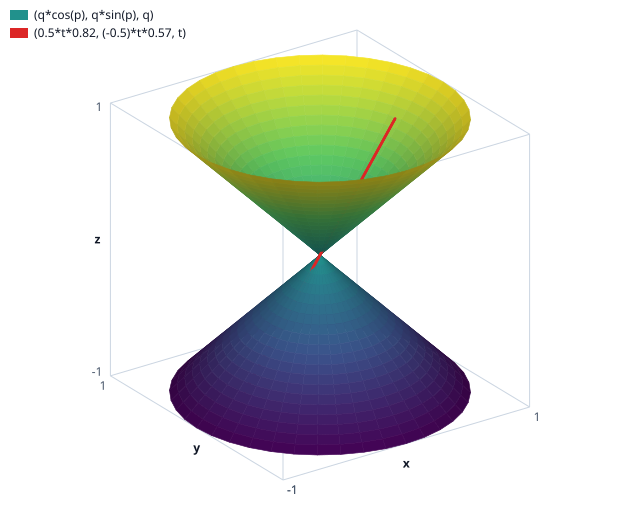

In [3]:
cone = surface(q*cos(p), q*sin(p), q, q, -1, 1, p, 0, 2*pi);
rocket = parametric3d(0.5*t*0.82, -0.5*t*0.57, t, t, -1, 1);
show(cone, rocket)

## 3. Lorentz transformations

A rotation keeps $x^2 + y^2$ unchanged. A **Lorentz boost**, the change to an observer moving at speed $v$, keeps
$-t^2 + x^2$ unchanged:

$$t' = \gamma\,(t - v x), \qquad x' = \gamma\,(x - v t), \qquad \gamma = \frac{1}{\sqrt{1 - v^2}}$$

For $v = 0.6$, $\gamma = 1.25$. As a matrix $\Lambda$ acting on $(t, x)$, the condition is
$\Lambda^T \eta\, \Lambda = \eta$, with $\eta$ the Minkowski metric:

In [4]:
L = [1.25, -0.75; -0.75, 1.25];
eta2 = [-1 0; 0 1];
transpose(L)*eta2*L

-1.0	0.0
0.0	1.0

Take the event $t = 5$, $x = 2$. The moving observer gives it different coordinates, but the same interval:

In [5]:
t1 = 1.25*(5 - 0.6*2)
x1 = 1.25*(2 - 0.6*5)
2^2 - 5^2
x1^2 - t1^2

4.75
-1.25
-21.0
-21.0

## 4. Proper time

A clock carried along a path through spacetime measures its **proper time** $\tau$, with $d\tau^2 = -ds^2$. For a clock
moving at speed $v$,

$$d\tau = \sqrt{dt^2 - dx^2} = \sqrt{1 - v^2}\;dt = dt/\gamma$$

Moving clocks run slow by the factor $\gamma$. It is small at everyday speeds and grows without bound as $v \to 1$:

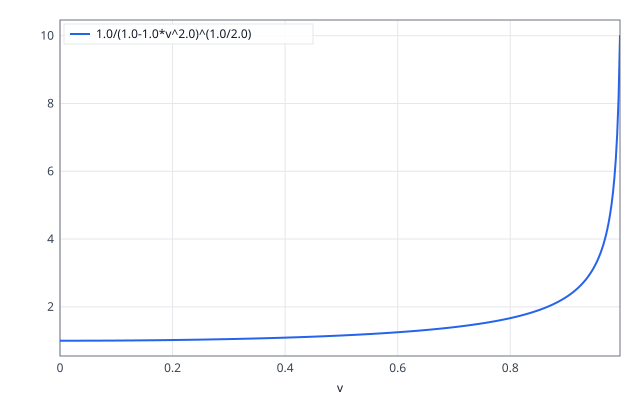

In [6]:
plot(1/sqrt(1 - v^2), v, 0, 0.995)

### Muons from the sky

Cosmic rays make muons about 15 km up. A muon lives about 2.2 microseconds [3], and at $v = 0.9995\,c$ it would cover only
660 m in that time, yet many reach the ground. Their clocks run slow by $\gamma$:

In [7]:
gam = eval(1/sqrt(1 - 0.9995^2))
eval(gam*2.2e-6*0.9995*299792458)

31.626730190074568
20848.771800107173

They live about 32 times longer and can travel about 21 km, more than enough. Frisch and Smith measured exactly this by counting muons on Mount Washington and at sea level [4].

## 5. The twin paradox

One twin stays home; the other flies out and back over 10 years, at speed $v(t) = 0.8\sin(\pi t/5)$. The traveller's
position is $x(t) = \tfrac{4}{\pi}\big(1 - \cos(\pi t/5)\big)$. In a spacetime diagram (time up):

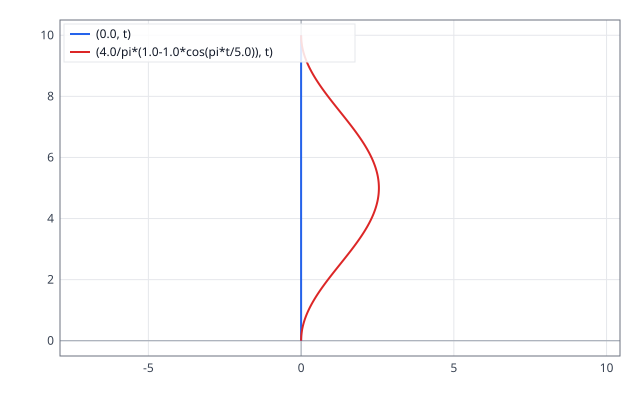

In [8]:
home = parametric(0, t, t, 0, 10);
trip = parametric(4/pi*(1 - cos(pi*t/5)), t, t, 0, 10);
show(home, trip)

The stay-at-home twin ages 10 years. The traveller's age is the proper time along the curved worldline,
$\int_0^{10}\sqrt{1 - v(t)^2}\,dt$:

In [9]:
odesolve([sqrt(1 - (0.8*sin(pi*t/5))^2)], [tau], t, [0], 0, 10)

8.125496102822186

The traveller comes back about two years younger. There is no paradox: the two paths through spacetime are different,
and the traveller's one is not straight (the traveller feels the accelerations).

In geometry a straight line is the *shortest* path; in spacetime, because of the minus sign, the straight worldline is
the one with the **longest** proper time. That is the principle general relativity builds on: free objects follow
the paths of longest proper time, the geodesics of spacetime.

## Summary

* Spacetime has the metric $ds^2 = -dt^2 + dx^2 + dy^2 + dz^2$; all observers agree on $ds^2$.
* Light cones separate timelike, null and spacelike directions.
* Lorentz boosts satisfy $\Lambda^T\eta\Lambda = \eta$.
* Proper time $d\tau = \sqrt{-ds^2}$; moving clocks run slow; straight worldlines maximise proper time.

**Try it:** make the trip faster, `0.95*sin(pi*t/5)`, and recompute the traveller's age.

Next: [The equivalence principle](02-equivalence-principle.ipynb), where gravity enters.

## Sources

Numbers in square brackets in the text refer to this list.

1. A. Einstein, "Zur Elektrodynamik bewegter Körper", *Annalen der Physik* **17**, 891–921 (1905). [doi:10.1002/andp.19053221004](https://doi.org/10.1002/andp.19053221004)
2. H. Minkowski, "Raum und Zeit", *Physikalische Zeitschrift* **10**, 104–111 (1909); lecture of 21 September 1908.
3. Particle Data Group, S. Navas et al., "Review of Particle Physics", *Physical Review D* **110**, 030001 (2024): muon mean life 2.1969811 µs; review "Cosmic rays" for muon production heights. [doi:10.1103/PhysRevD.110.030001](https://doi.org/10.1103/PhysRevD.110.030001)
4. D. H. Frisch and J. H. Smith, "Measurement of the relativistic time dilation using μ-mesons", *American Journal of Physics* **31**, 342–355 (1963). [doi:10.1119/1.1969508](https://doi.org/10.1119/1.1969508)
5. S. M. Carroll, *Spacetime and Geometry: An Introduction to General Relativity*, Addison-Wesley (2004). Chapter 1.